# Baseline 1D CNN for PTB-XL Myocardial Infarction Detection

In [2]:
from __future__ import annotations

import json
import random
import logging
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import wfdb
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, classification_report, RocCurveDisplay,
    PrecisionRecallDisplay,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)


PyTorch: 2.15.0+cu132
Device: cuda


## Step 1: Project paths and metadata

In [3]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "ptb-xl"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CONFIG_PATH = PROJECT_ROOT / "results" / "preprocessing" / "preprocessing_config.json"
RESULTS_DIR = PROJECT_ROOT / "results" / "baseline_cnn"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

DATABASE_PATH = DATA_ROOT / "ptbxl_database.csv"
LABEL_PATH = PROCESSED_DIR / "ptbxl_labels.csv"
if not DATABASE_PATH.exists():
    raise FileNotFoundError(f"Missing metadata file: {DATABASE_PATH}")
if not LABEL_PATH.exists():
    raise FileNotFoundError(f"Missing label file: {LABEL_PATH}")

metadata = pd.read_csv(DATABASE_PATH, index_col="ecg_id")
labels = pd.read_csv(LABEL_PATH, index_col="ecg_id")

if not {"patient_id", "filename_hr"}.issubset(metadata.columns):
    raise ValueError("Metadata must contain patient_id and filename_hr.")
if not {"patient_id", "mi_label", "dataset_split"}.issubset(labels.columns):
    raise ValueError("Labels must contain patient_id, mi_label, dataset_split.")
if set(metadata.index) != set(labels.index):
    raise ValueError("Metadata and labels have different ECG IDs.")

labels = labels.loc[metadata.index]
if not np.array_equal(metadata["patient_id"].to_numpy(), labels["patient_id"].to_numpy()):
    raise ValueError("Patient IDs disagree between metadata and label files.")

print("Records:", len(metadata))
display(labels.groupby("dataset_split")["mi_label"].agg(["count", "sum", "mean"]))

Records: 21799


,count,sum,mean
dataset_split,,,
test,2198,532,0.242038
train,17418,4235,0.243139
validation,2183,521,0.238662


## Step 2: Split integrity checks

In [4]:
expected_splits = {"train", "validation", "test"}
if set(labels["dataset_split"].dropna().unique()) != expected_splits:
    raise ValueError("Expected train, validation, and test split labels.")
if labels[["patient_id", "mi_label", "dataset_split"]].isna().any().any():
    raise ValueError("Missing patient ID, target, or split.")
if not set(labels["mi_label"].astype(int).unique()).issubset({0, 1}):
    raise ValueError("mi_label must be binary.")

patient_split_count = labels.groupby("patient_id")["dataset_split"].nunique()
leaks = patient_split_count[patient_split_count > 1]
if len(leaks):
    raise ValueError(f"Patient leakage detected: {len(leaks)} patients occur in multiple splits.")
print("Patient-level split check passed.")

Patient-level split check passed.


## Step 3: Load preprocessing configuration

In [5]:
if CONFIG_PATH.exists():
    with CONFIG_PATH.open("r", encoding="utf-8") as file:
        PREPROCESSING_CONFIG = json.load(file)
    print("Loaded:", CONFIG_PATH)
else:
    PREPROCESSING_CONFIG = {"bandpass": {"enabled": False}, "notch": {"enabled": False}}
    print("No preprocessing config found; raw ECGs will be used.")

print(json.dumps(PREPROCESSING_CONFIG, indent=2))

Loaded: c:\Users\sintu\Desktop\Myocardial Infarction\results\preprocessing\preprocessing_config.json
{
  "source_sampling_rate_hz": 500.0,
  "target_sampling_rate_hz": 500.0,
  "preserve_raw_signal": true,
  "bandpass": {
    "enabled": true,
    "type": "butterworth",
    "low_hz": 0.5,
    "high_hz": 40.0,
    "order": 4,
    "implementation": "scipy.signal.sosfiltfilt",
    "zero_phase": true
  },
  "notch": {
    "enabled": false,
    "frequency_hz": 50.0,
    "quality_factor": 30.0,
    "implementation": "scipy.signal.filtfilt",
    "reason_disabled": "The 40 Hz low-pass already attenuates 50 Hz mains interference; do not apply a redundant 50 Hz notch after this band-pass."
  },
  "normalization": {
    "enabled": false,
    "method": null,
    "fit_on_training_data_only": true
  },
  "notes": "Provisional configuration. Compare filter settings and inspect morphology before full processing. A 0.5 Hz high-pass can alter ST-segment morphology; include a lower-cutoff sensitivity anal

## Step 4: Signal preprocessing functions

In [6]:
def apply_bandpass(
    signal: np.ndarray,
    sampling_rate: float,
    low_hz: float,
    high_hz: float,
    order: int,
) -> np.ndarray:
    if not (0 < low_hz < high_hz < sampling_rate / 2):
        raise ValueError("Cutoffs must satisfy 0 < low < high < Nyquist.")
    sos = butter(
        order, [low_hz, high_hz], btype="bandpass",
        fs=sampling_rate, output="sos"
    )
    return sosfiltfilt(sos, signal, axis=0).astype(np.float32)


def apply_notch(
    signal: np.ndarray,
    sampling_rate: float,
    frequency_hz: float,
    quality_factor: float,
) -> np.ndarray:
    if not (0 < frequency_hz < sampling_rate / 2):
        raise ValueError("Notch frequency must be below Nyquist.")
    b, a = iirnotch(frequency_hz, quality_factor, fs=sampling_rate)
    return filtfilt(b, a, signal, axis=0).astype(np.float32)


def preprocess_signal(
    signal: np.ndarray,
    sampling_rate: float,
    config: dict[str, Any],
) -> np.ndarray:
    output = np.asarray(signal, dtype=np.float32).copy()

    bp = config.get("bandpass", {})
    if bp.get("enabled", False):
        output = apply_bandpass(
            output, sampling_rate, float(bp["low_hz"]),
            float(bp["high_hz"]), int(bp["order"])
        )

    notch = config.get("notch", {})
    if notch.get("enabled", False):
        output = apply_notch(
            output, sampling_rate, float(notch["frequency_hz"]),
            float(notch["quality_factor"])
        )

    if not np.isfinite(output).all():
        raise ValueError("Preprocessing generated NaN or infinity.")
    return output

## Step 5: Lazy-loading PyTorch Dataset

In [7]:
class PTBXLMIDataset(Dataset):
    def __init__(
        self,
        metadata_frame: pd.DataFrame,
        labels_frame: pd.DataFrame,
        data_root: Path,
        split: str,
        preprocessing_config: dict[str, Any],
    ) -> None:
        self.data_root = Path(data_root)
        self.config = preprocessing_config
        selected_ids = labels_frame.index[labels_frame["dataset_split"] == split]
        self.metadata = metadata_frame.loc[selected_ids].copy()
        self.targets = labels_frame.loc[selected_ids, "mi_label"].astype(int)

        if self.metadata.empty:
            raise ValueError(f"No records found for split: {split}")

    def __len__(self) -> int:
        return len(self.metadata)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        ecg_id = int(self.metadata.index[index])
        relative_path = str(self.metadata.iloc[index]["filename_hr"])
        signal, fields = wfdb.rdsamp(str(self.data_root / relative_path))
        signal = np.asarray(signal, dtype=np.float32)
        fs = float(fields["fs"])

        if fs != 500.0:
            raise ValueError(f"ECG {ecg_id}: expected 500 Hz, received {fs} Hz.")
        if signal.shape != (5000, 12):
            raise ValueError(f"ECG {ecg_id}: expected (5000, 12), got {signal.shape}.")
        if not np.isfinite(signal).all():
            raise ValueError(f"ECG {ecg_id} contains non-finite samples.")

        signal = preprocess_signal(signal, fs, self.config)
        signal = np.ascontiguousarray(signal.T, dtype=np.float32)
        x = torch.from_numpy(signal)
        y = torch.tensor(float(self.targets.iloc[index]), dtype=torch.float32)
        return x, y


train_dataset = PTBXLMIDataset(metadata, labels, DATA_ROOT, "train", PREPROCESSING_CONFIG)
validation_dataset = PTBXLMIDataset(metadata, labels, DATA_ROOT, "validation", PREPROCESSING_CONFIG)
test_dataset = PTBXLMIDataset(metadata, labels, DATA_ROOT, "test", PREPROCESSING_CONFIG)

print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))

Train: 17418
Validation: 2183
Test: 2198


## Step 6: DataLoaders and batch validation

In [8]:
BATCH_SIZE = 32
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == "cuda"

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)

x_batch, y_batch = next(iter(train_loader))
print("ECG batch shape:", tuple(x_batch.shape))
print("Target batch shape:", tuple(y_batch.shape))
assert x_batch.ndim == 3 and x_batch.shape[1:] == (12, 5000)
assert torch.isfinite(x_batch).all()

ECG batch shape: (32, 12, 5000)
Target batch shape: (32,)


## Step 7: Baseline 1D CNN architecture

In [9]:
class ECG1DCNN(nn.Module):
    def __init__(self, in_channels: int = 12, dropout: float = 0.30) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(in_channels, 32, kernel_size=15, stride=2, padding=7, bias=False),
            nn.BatchNorm1d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=3, stride=2, padding=1),

            nn.Conv1d(32, 64, kernel_size=9, stride=2, padding=4, bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=3, stride=2, padding=1),

            nn.Conv1d(64, 128, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),

            nn.Conv1d(128, 192, kernel_size=5, stride=1, padding=2, bias=False),
            nn.BatchNorm1d(192),
            nn.ReLU(inplace=True),
        )
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(192, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x).squeeze(1)


model = ECG1DCNN().to(DEVICE)
with torch.no_grad():
    logits_example = model(x_batch.to(DEVICE))
print("Output shape:", tuple(logits_example.shape))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Output shape: (32,)
Trainable parameters: 217665


## Step 8: Loss, optimizer, scheduler

In [10]:
USE_POS_WEIGHT = False
train_targets = labels.loc[labels["dataset_split"] == "train", "mi_label"].astype(int)
n_positive = int((train_targets == 1).sum())
n_negative = int((train_targets == 0).sum())
if n_positive == 0:
    raise ValueError("No positive examples in training data.")

positive_weight = torch.tensor(
    [n_negative / n_positive], dtype=torch.float32, device=DEVICE
)
criterion = (
    nn.BCEWithLogitsLoss(pos_weight=positive_weight)
    if USE_POS_WEIGHT else nn.BCEWithLogitsLoss()
)

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3
)

print("Training positives:", n_positive)
print("Training negatives:", n_negative)
print("Positive weight:", positive_weight.item())
print("Using positive weight:", USE_POS_WEIGHT)

Training positives: 4235
Training negatives: 13183
Positive weight: 3.1128690242767334
Using positive weight: False


## Step 9 : Training and prediction utilities

In [11]:
def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
) -> float:
    model.train()
    loss_sum = 0.0
    count = 0

    for signals, targets in loader:
        signals = signals.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(signals)
        loss = criterion(logits, targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        batch_count = signals.size(0)
        loss_sum += float(loss.item()) * batch_count
        count += batch_count

    return loss_sum / count


@torch.no_grad()
def predict_probabilities(
    model: nn.Module,
    loader: DataLoader,
) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    probabilities = []
    targets_all = []

    for signals, targets in loader:
        signals = signals.to(DEVICE, non_blocking=True)
        probs = torch.sigmoid(model(signals))
        probabilities.append(probs.cpu().numpy())
        targets_all.append(targets.numpy())

    return np.concatenate(targets_all).astype(int), np.concatenate(probabilities)


@torch.no_grad()
def evaluate_loss(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
) -> float:
    model.eval()
    loss_sum = 0.0
    count = 0
    for signals, targets in loader:
        signals = signals.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        loss = criterion(model(signals), targets)
        loss_sum += float(loss.item()) * signals.size(0)
        count += signals.size(0)
    return loss_sum / count

## Step 10: Train with early stopping

In [12]:
MAX_EPOCHS = 30
PATIENCE = 7
CHECKPOINT_PATH = CHECKPOINT_DIR / "baseline_ecg_1dcnn_best.pt"

history = []
best_val_auc = -np.inf
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss = evaluate_loss(model, validation_loader, criterion)
    y_val, p_val = predict_probabilities(model, validation_loader)

    if np.unique(y_val).size != 2:
        raise ValueError("Validation split must contain both target classes.")
    val_auc = roc_auc_score(y_val, p_val)
    val_ap = average_precision_score(y_val, p_val)
    scheduler.step(val_auc)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_roc_auc": val_auc,
        "validation_pr_auc": val_ap,
        "learning_rate": optimizer.param_groups[0]["lr"],
    })

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | train_loss={train_loss:.4f} "
        f"| val_loss={val_loss:.4f} | val_ROC_AUC={val_auc:.4f} "
        f"| val_PR_AUC={val_ap:.4f}"
    )

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        epochs_without_improvement = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "validation_roc_auc": val_auc,
            "preprocessing_config": PREPROCESSING_CONFIG,
            "seed": SEED,
        }, CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

history_df = pd.DataFrame(history)
display(history_df.tail())
print("Best validation ROC-AUC:", best_val_auc)
print("Saved checkpoint:", CHECKPOINT_PATH.resolve())

Epoch 01/30 | train_loss=0.3673 | val_loss=0.3095 | val_ROC_AUC=0.9118 | val_PR_AUC=0.7981
Epoch 02/30 | train_loss=0.3085 | val_loss=0.3482 | val_ROC_AUC=0.9229 | val_PR_AUC=0.8198
Epoch 03/30 | train_loss=0.2853 | val_loss=0.4457 | val_ROC_AUC=0.9221 | val_PR_AUC=0.7970
Epoch 04/30 | train_loss=0.2763 | val_loss=0.3232 | val_ROC_AUC=0.9229 | val_PR_AUC=0.8292
Epoch 05/30 | train_loss=0.2658 | val_loss=0.2803 | val_ROC_AUC=0.9332 | val_PR_AUC=0.8471
Epoch 06/30 | train_loss=0.2615 | val_loss=0.2810 | val_ROC_AUC=0.9291 | val_PR_AUC=0.8363
Epoch 07/30 | train_loss=0.2530 | val_loss=0.3253 | val_ROC_AUC=0.9194 | val_PR_AUC=0.8059
Epoch 08/30 | train_loss=0.2470 | val_loss=0.3076 | val_ROC_AUC=0.9301 | val_PR_AUC=0.8367
Epoch 09/30 | train_loss=0.2480 | val_loss=0.3138 | val_ROC_AUC=0.9331 | val_PR_AUC=0.8406
Epoch 10/30 | train_loss=0.2281 | val_loss=0.2724 | val_ROC_AUC=0.9366 | val_PR_AUC=0.8449
Epoch 11/30 | train_loss=0.2261 | val_loss=0.2825 | val_ROC_AUC=0.9342 | val_PR_AUC=0.8357

,epoch,train_loss,validation_loss,validation_roc_auc,validation_pr_auc,learning_rate
15,16,0.209170,0.280514,0.934028,0.838088,0.00050
16,17,0.209529,0.276299,0.934044,0.840459,0.00025
17,18,0.194411,0.288285,0.937010,0.845221,0.00025
18,19,0.192118,0.282636,0.934441,0.835282,0.00025
19,20,0.186169,0.302879,0.934327,0.834767,0.00025


Best validation ROC-AUC: 0.9373093029003282
Saved checkpoint: C:\Users\sintu\Desktop\Myocardial Infarction\checkpoints\baseline_ecg_1dcnn_best.pt


## Step 11: Training curves

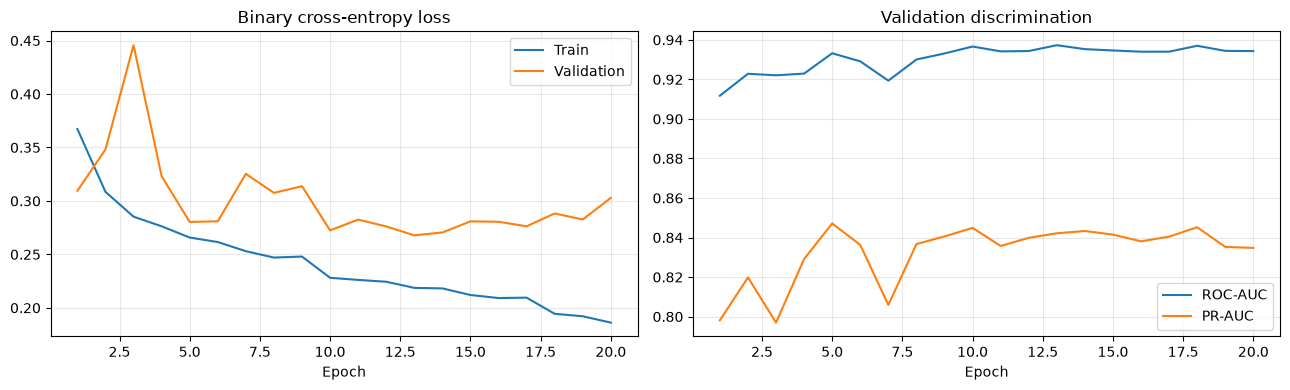

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0].plot(history_df["epoch"], history_df["validation_loss"], label="Validation")
axes[0].set_title("Binary cross-entropy loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["validation_roc_auc"], label="ROC-AUC")
axes[1].plot(history_df["epoch"], history_df["validation_pr_auc"], label="PR-AUC")
axes[1].set_title("Validation discrimination")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 12: Select classification threshold on validation data

In [14]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])

y_val, p_val = predict_probabilities(model, validation_loader)
threshold_results = []

for threshold in np.arange(0.05, 0.951, 0.01):
    pred = (p_val >= threshold).astype(int)
    tn_v, fp_v, fn_v, tp_v = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    threshold_results.append({
        "threshold": float(threshold),
        "f1": f1_score(y_val, pred, zero_division=0),
        "sensitivity": recall_score(y_val, pred, zero_division=0),
        "specificity": tn_v / (tn_v + fp_v) if (tn_v + fp_v) else np.nan,
        "precision": precision_score(y_val, pred, zero_division=0),
    })

threshold_df = pd.DataFrame(threshold_results)
best_threshold = float(threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"])
display(threshold_df.sort_values("f1", ascending=False).head(10))
print("Selected validation threshold:", best_threshold)

,threshold,f1,sensitivity,specificity,precision
39,0.44,0.763533,0.771593,0.921781,0.755639
38,0.43,0.762984,0.775432,0.919374,0.750929
37,0.42,0.762441,0.779271,0.916968,0.746324
28,0.33,0.761572,0.836852,0.886883,0.698718
32,0.37,0.761476,0.811900,0.899519,0.716949
27,0.32,0.761324,0.838772,0.885680,0.696970
31,0.36,0.760714,0.817658,0.895909,0.711185
30,0.35,0.760389,0.825336,0.891697,0.704918
29,0.34,0.759894,0.829175,0.889290,0.701299
36,0.41,0.759777,0.783109,0.912756,0.737794


Selected validation threshold: 0.44000000000000006


## STep 13: One-time test evaluation

In [15]:
y_test, p_test = predict_probabilities(model, test_loader)
test_pred = (p_test >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()

test_metrics = {
    "threshold": best_threshold,
    "accuracy": accuracy_score(y_test, test_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "sensitivity_recall": recall_score(y_test, test_pred, zero_division=0),
    "specificity": tn / (tn + fp) if (tn + fp) else float("nan"),
    "f1": f1_score(y_test, test_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, p_test),
    "pr_auc_average_precision": average_precision_score(y_test, p_test),
    "mcc": matthews_corrcoef(y_test, test_pred),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
}

display(pd.Series(test_metrics, name="test_value").to_frame())
print(classification_report(
    y_test, test_pred, target_names=["Non-MI", "MI"], zero_division=0
))

,test_value
threshold,0.440000
accuracy,0.873066
balanced_accuracy,0.825425
precision,0.740038
sensitivity_recall,0.733083
specificity,0.917767
f1,0.736544
roc_auc,0.930310
pr_auc_average_precision,0.834597
mcc,0.652951


              precision    recall  f1-score   support

      Non-MI       0.92      0.92      0.92      1666
          MI       0.74      0.73      0.74       532

    accuracy                           0.87      2198
   macro avg       0.83      0.83      0.83      2198
weighted avg       0.87      0.87      0.87      2198



## Step 14: Confusion matrix, ROC curve, and precision-recall curve

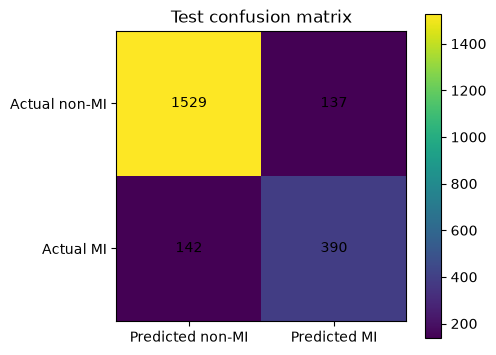

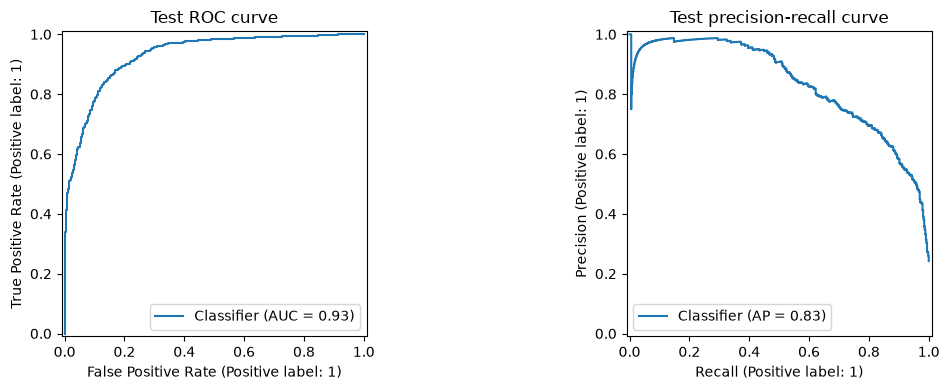

In [16]:
fig, ax = plt.subplots(figsize=(5, 4))
cm = np.array([[tn, fp], [fn, tp]])
im = ax.imshow(cm)
ax.set_xticks([0, 1], labels=["Predicted non-MI", "Predicted MI"])
ax.set_yticks([0, 1], labels=["Actual non-MI", "Actual MI"])
ax.set_title("Test confusion matrix")
for (row, col), value in np.ndenumerate(cm):
    ax.text(col, row, str(value), ha="center", va="center")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[0])
axes[0].set_title("Test ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[1])
axes[1].set_title("Test precision-recall curve")
plt.tight_layout()
plt.show()

## Step 15: Save metrics, history, and experiment configuration

In [17]:
history_path = RESULTS_DIR / "training_history.csv"
metrics_path = RESULTS_DIR / "test_metrics.json"
threshold_path = RESULTS_DIR / "validation_threshold_search.csv"
experiment_path = RESULTS_DIR / "experiment_config.json"

history_df.to_csv(history_path, index=False)
threshold_df.to_csv(threshold_path, index=False)
with metrics_path.open("w", encoding="utf-8") as file:
    json.dump(test_metrics, file, indent=4)

experiment_config = {
    "model": "ECG1DCNN",
    "seed": SEED,
    "input_shape": [12, 5000],
    "sampling_rate_hz": 500,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "BCEWithLogitsLoss",
    "use_pos_weight": USE_POS_WEIGHT,
    "training_positive_weight": float(positive_weight.item()),
    "threshold_rule": "maximum validation F1",
    "selected_threshold": best_threshold,
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_roc_auc": float(checkpoint["validation_roc_auc"]),
    "preprocessing": PREPROCESSING_CONFIG,
}
with experiment_path.open("w", encoding="utf-8") as file:
    json.dump(experiment_config, file, indent=4)

print("Saved files:")
for path in [history_path, metrics_path, threshold_path, experiment_path, CHECKPOINT_PATH]:
    print(path.resolve())

Saved files:
C:\Users\sintu\Desktop\Myocardial Infarction\results\baseline_cnn\training_history.csv
C:\Users\sintu\Desktop\Myocardial Infarction\results\baseline_cnn\test_metrics.json
C:\Users\sintu\Desktop\Myocardial Infarction\results\baseline_cnn\validation_threshold_search.csv
C:\Users\sintu\Desktop\Myocardial Infarction\results\baseline_cnn\experiment_config.json
C:\Users\sintu\Desktop\Myocardial Infarction\checkpoints\baseline_ecg_1dcnn_best.pt
